In [85]:
import numpy as np
import pandas as pd

In [86]:
df = pd.read_csv("spam.csv", encoding='latin-1')

In [87]:
df.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
1852,spam,This is the 2nd time we have tried 2 contact u...,NaN,NaN,NaN
1465,spam,YOU 07801543489 are guaranteed the latests Nok...,NaN,NaN,NaN
3598,ham,Then wat r u doing now? Busy wif work?,NaN,NaN,NaN
3858,spam,Win the newest åÒHarry Potter and the Order of...,NaN,NaN,NaN
5052,ham,Lmao you know me so well...,NaN,NaN,NaN


In [88]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [89]:
df.shape

(5572, 5)

In [90]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [91]:
df.describe(include="all")

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
count,5572,5572,50,12,6
unique,2,5169,43,10,5
top,ham,"Sorry, I'll call later","bt not his girlfrnd... G o o d n i g h t . . .@""","MK17 92H. 450Ppw 16""","GNT:-)"""
freq,4825,30,3,2,2


In [92]:
df.isnull().sum()

,0
v1,0
v2,0
Unnamed: 2,5522
Unnamed: 3,5560
Unnamed: 4,5566


In [93]:
df.drop(columns=['Unnamed: 2','Unnamed: 3','Unnamed: 4'],inplace=True)

In [94]:
df.isnull().sum()

,0
v1,0
v2,0


In [95]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 403


In [96]:
# renaming the cols
df.rename(columns={'v1':'target','v2':'text'},inplace=True)
df.sample(5)

,target,text
3167,ham,Ugh hopefully the asus ppl dont randomly do a ...
96,ham,Watching telugu movie..wat abt u?
1758,ham,Sorry i'm not free...
3181,ham,"My Parents, My Kidz, My Friends n My Colleague..."
4624,ham,I'm on the bus. Love you


In [97]:
df.dtypes

,0
target,object
text,object


In [98]:
# Check the column names
print(df.columns)

# Check the target labels
print(df['target'].value_counts())

# Check missing values
print(df.isnull().sum())

# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Reset the index
df.reset_index(drop=True, inplace=True)

# Check the dataset after cleaning
print("Dataset shape:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())
print("Missing values:\n", df.isnull().sum())

Index(['target', 'text'], dtype='object')
target
ham     4825
spam     747
Name: count, dtype: int64
target    0
text      0
dtype: int64
Dataset shape: (5169, 2)
Duplicate rows remaining: 0
Missing values:
 target    0
text      0
dtype: int64


In [99]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [100]:
df['target'] = df['target'].map({
    'ham': 0,
    'spam': 1
})

print(df['target'].value_counts())
print(df[['text', 'target']].sample(5))

target
0    4516
1     653
Name: count, dtype: int64
                                                   text  target
1096  Do you want 750 anytime any network mins 150 t...       1
512      But that's on ebay it might be less elsewhere.       0
1727                         Yes:)sura in sun tv.:)lol.       0
2782                   Are you coming to day for class.       0
316   Merry Christmas to you too babe, i love ya *ki...       0


In [101]:
df['target'] = encoder.fit_transform(df['target'])

In [102]:
df.shape

(5169, 2)

target
0    4516
1     653
Name: count, dtype: int64


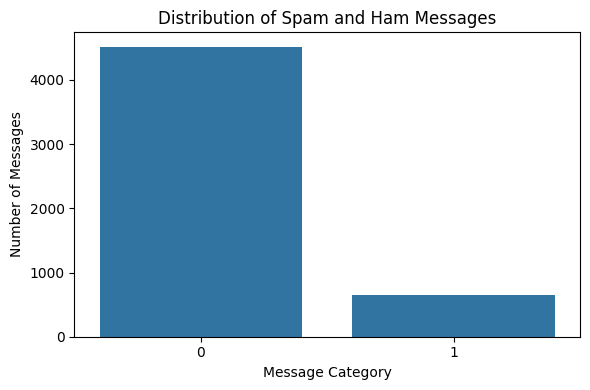

In [103]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count ham and spam messages
print(df['target'].value_counts())

# Visualize the class distribution
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='target')

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=300)
plt.show()

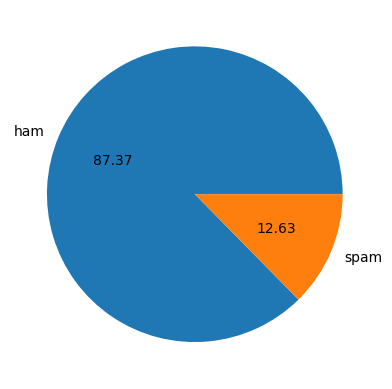

In [104]:
import matplotlib.pyplot as plt
plt.pie(df['target'].value_counts(), labels=['ham','spam'],autopct="%0.2f")
plt.show()

         count        mean        std   min    25%    50%    75%    max
target                                                                 
0       4516.0   70.459256  56.358207   2.0   34.0   52.0   90.0  910.0
1        653.0  137.891271  30.137753  13.0  132.0  149.0  157.0  224.0


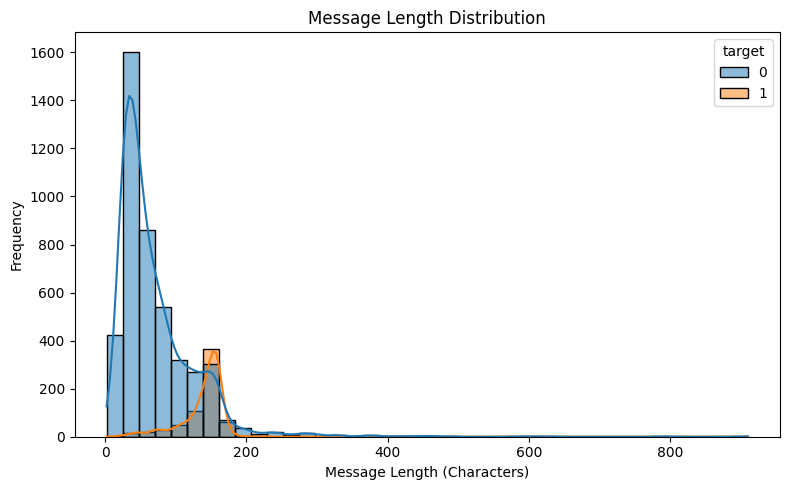

In [105]:
# Calculate the length of each message
df['message_length'] = df['text'].str.len()

# Compare message lengths
print(df.groupby('target')['message_length'].describe())

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='message_length',
    hue='target',
    bins=40,
    kde=True
)

plt.title("Message Length Distribution")
plt.xlabel("Message Length (Characters)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("message_length_distribution.png", dpi=300)
plt.show()

In [106]:
from sklearn.model_selection import train_test_split

X = df['text']
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4135
Testing samples: 1034


In [107]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

model = Pipeline([
    ('tfidf', TfidfVectorizer(
        lowercase=True,
        stop_words='english',
        ngram_range=(1, 2)
    )),
    ('classifier', MultinomialNB())
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [108]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predict the test messages
y_pred = model.predict(X_test)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Ham', 'Spam'],
    zero_division=0
))

Accuracy:  0.9536
Precision: 1.0000
Recall:    0.6336
F1-score:  0.7757

Classification Report:
              precision    recall  f1-score   support

         Ham       0.95      1.00      0.97       903
        Spam       1.00      0.63      0.78       131

    accuracy                           0.95      1034
   macro avg       0.97      0.82      0.87      1034
weighted avg       0.96      0.95      0.95      1034



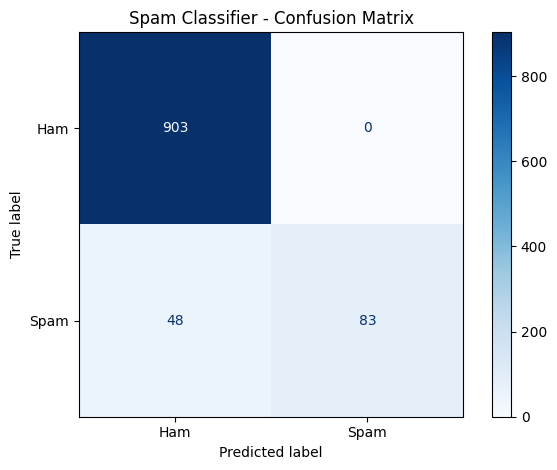

In [109]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Ham', 'Spam']
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Spam Classifier - Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

In [110]:
# Get spam probabilities
probabilities = model.predict_proba(X_test)

# Get predicted labels
predictions = model.predict(X_test)

# Create a results table
example_predictions = pd.DataFrame({
    'message': X_test.reset_index(drop=True),
    'actual_label': y_test.reset_index(drop=True).map({
        0: 'ham',
        1: 'spam'
    }),
    'predicted_label': pd.Series(predictions).map({
        0: 'ham',
        1: 'spam'
    }),
    'spam_probability': probabilities[:, 1],
    'confidence': probabilities.max(axis=1)
})

# Select 10 examples
example_predictions = example_predictions.head(10)

print(example_predictions.to_string(index=False))

# Save the results
example_predictions.to_csv(
    "example_predictions.csv",
    index=False
)

                                                                                                                                                        message actual_label predicted_label  spam_probability  confidence
Good morning, my Love ... I go to sleep now and wish you a great day full of feeling better and opportunity ... You are my last thought babe, I LOVE YOU *kiss*          ham             ham          0.000484    0.999516
                                                                                                                         And how you will do that, princess? :)          ham             ham          0.022650    0.977350
                                                                                                                 Nope. Meanwhile she talk say make i greet you.          ham             ham          0.010030    0.989970
                                                                                                 Designation is software dev

In [111]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    BaggingClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd
import numpy as np
import time

In [112]:
%pip install xgboost

In [113]:
from xgboost import XGBClassifier

In [115]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "SVM": SVC(kernel='linear', probability=True, random_state=42),

    "Naive Bayes": MultinomialNB(),

    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "KNN": KNeighborsClassifier(n_neighbors=5),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "AdaBoost": AdaBoostClassifier(random_state=42),

    "Bagging": BaggingClassifier(random_state=42, n_jobs=-1),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(random_state=42),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    )
}

In [116]:
results = []
trained_models = {}
failed_models = {}

for name, classifier in models.items():

    print(f"Training {name}...")

    try:
        start_time = time.time()

        model = Pipeline([
            ('tfidf', TfidfVectorizer(
                lowercase=True,
                stop_words='english',
                ngram_range=(1, 2),
                max_features=5000
            )),
            ('classifier', classifier)
        ])

        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(
            y_test, y_pred, zero_division=0
        )
        recall = recall_score(
            y_test, y_pred, zero_division=0
        )
        f1 = f1_score(
            y_test, y_pred, zero_division=0
        )

        elapsed_time = time.time() - start_time

        results.append({
            'Model': name,
            'Accuracy': accuracy,
            'Precision': precision,
            'Recall': recall,
            'F1-Score': f1,
            'Training Time (seconds)': round(elapsed_time, 2)
        })

        trained_models[name] = model

        print(f"F1-score: {f1:.4f}")
        print(f"Completed in {elapsed_time:.2f} seconds\n")

    except Exception as e:
        failed_models[name] = str(e)
        print(f"Could not train {name}: {e}\n")

Training Logistic Regression...
F1-score: 0.8000
Completed in 0.50 seconds

Training SVM...
F1-score: 0.9187
Completed in 6.52 seconds

Training Naive Bayes...
F1-score: 0.8571
Completed in 0.43 seconds

Training Decision Tree...
F1-score: 0.8392
Completed in 1.26 seconds

Training KNN...
F1-score: 0.4024
Completed in 0.66 seconds

Training Random Forest...
F1-score: 0.8963
Completed in 1.54 seconds

Training AdaBoost...
F1-score: 0.5525
Completed in 0.82 seconds

Training Bagging...
F1-score: 0.8413
Completed in 4.59 seconds

Training Extra Trees...
F1-score: 0.9143
Completed in 3.09 seconds

Training Gradient Boosting...
F1-score: 0.8125
Completed in 2.71 seconds

Training XGBoost...
F1-score: 0.7890
Completed in 0.97 seconds



In [117]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1-Score',
    ascending=False
).reset_index(drop=True)

print(results_df.to_string(index=False))

results_df.to_csv(
    "model_comparison.csv",
    index=False
)

              Model  Accuracy  Precision   Recall  F1-Score  Training Time (seconds)
                SVM  0.980658   0.982609 0.862595  0.918699                     6.52
        Extra Trees  0.979691   0.982456 0.854962  0.914286                     3.09
      Random Forest  0.975822   0.981818 0.824427  0.896266                     1.54
        Naive Bayes  0.968085   0.990000 0.755725  0.857143                     0.43
            Bagging  0.961315   0.876033 0.809160  0.841270                     4.59
      Decision Tree  0.960348   0.862903 0.816794  0.839216                     1.26
  Gradient Boosting  0.959381   0.978495 0.694656  0.812500                     2.71
Logistic Regression  0.957447   0.988764 0.671756  0.800000                     0.50
            XGBoost  0.955513   0.988506 0.656489  0.788991                     0.97
           AdaBoost  0.921663   1.000000 0.381679  0.552486                     0.82
                KNN  0.905222   1.000000 0.251908  0.402439      

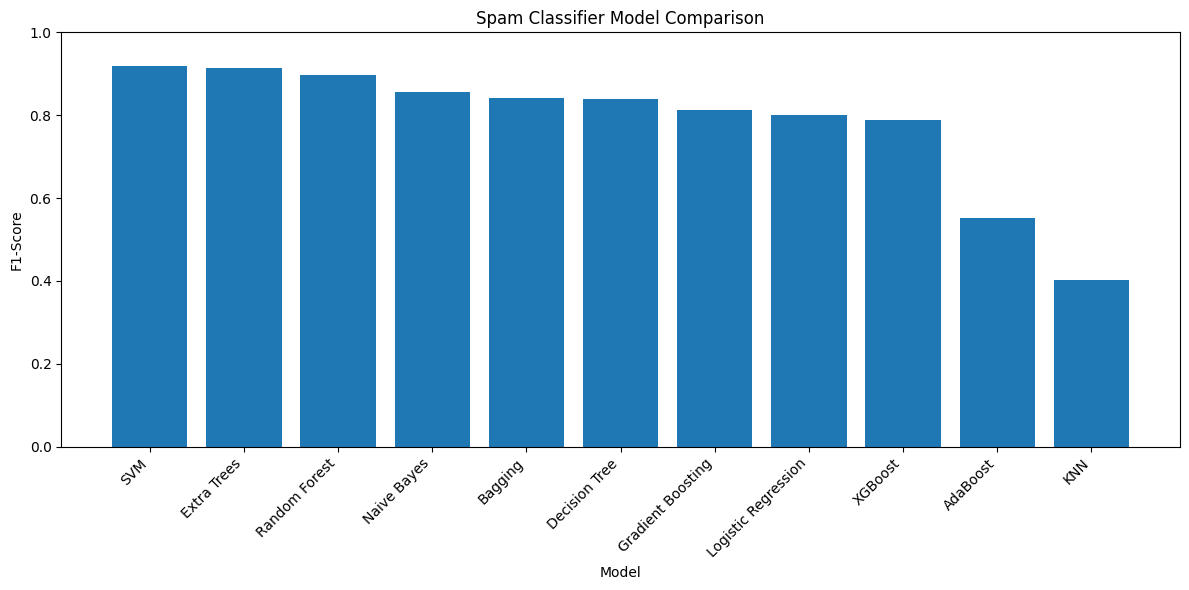

In [118]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    results_df['Model'],
    results_df['F1-Score']
)

plt.title("Spam Classifier Model Comparison")
plt.xlabel("Model")
plt.ylabel("F1-Score")
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig("model_comparison.png", dpi=300)
plt.show()

In [119]:
import joblib

if results_df.empty:
    print("No models trained successfully.")
else:
    best_model_name = results_df.iloc[0]['Model']
    best_model = trained_models[best_model_name]

    joblib.dump(best_model, "spam_classifier.pkl")

    print("Best model:", best_model_name)
    print("F1-score:", results_df.iloc[0]['F1-Score'])
    print("Saved as spam_classifier.pkl")

Best model: SVM
F1-score: 0.9186991869918699
Saved as spam_classifier.pkl


Confusion Matrix:
[[901   2]
 [ 18 113]]


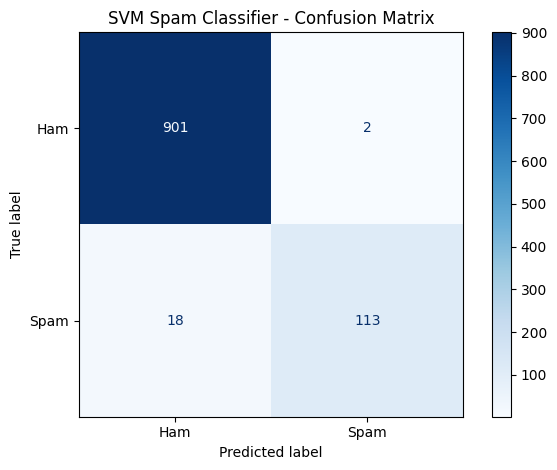

Confusion matrix saved successfully!


In [123]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Get the trained SVM model
best_model = trained_models["SVM"]

# Predict test data
y_pred = best_model.predict(X_test)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("SVM Spam Classifier - Confusion Matrix")
plt.tight_layout()

# Save image
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix saved successfully!")

In [124]:
import pandas as pd
import numpy as np

# Use your trained SVM model
best_model = trained_models["SVM"]

# Predict labels and probabilities
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)

# Create prediction results
example_predictions = pd.DataFrame({
    "Message": X_test.reset_index(drop=True),
    "Actual Label": y_test.reset_index(drop=True).map({
        0: "Ham",
        1: "Spam"
    }),
    "Predicted Label": pd.Series(y_pred).map({
        0: "Ham",
        1: "Spam"
    }),
    "Spam Probability (%)": np.round(y_prob[:, 1] * 100, 2),
    "Confidence (%)": np.round(
        np.max(y_prob, axis=1) * 100, 2
    )
})

# Select 10 examples
example_predictions = example_predictions.head(10)

# Display results
print(example_predictions.to_string(index=False))

# Save results
example_predictions.to_csv(
    "example_predictions.csv",
    index=False
)

print("\nExample predictions saved successfully!")

                                                                                                                                                        Message Actual Label Predicted Label  Spam Probability (%)  Confidence (%)
Good morning, my Love ... I go to sleep now and wish you a great day full of feeling better and opportunity ... You are my last thought babe, I LOVE YOU *kiss*          Ham             Ham                  0.18           99.82
                                                                                                                         And how you will do that, princess? :)          Ham             Ham                  0.10           99.90
                                                                                                                 Nope. Meanwhile she talk say make i greet you.          Ham             Ham                  0.94           99.06
                                                                                            

In [125]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Use predictions from the best SVM model
best_model = trained_models["SVM"]
y_pred = best_model.predict(X_test)

# Calculate evaluation metrics
metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ]
})

print(metrics_df.to_string(index=False))

# Save metrics
metrics_df.to_csv("metrics.csv", index=False)

print("\nMetrics saved successfully!")

   Metric    Score
 Accuracy 0.980658
Precision 0.982609
   Recall 0.862595
 F1-Score 0.918699

Metrics saved successfully!


In [128]:
requirements = """numpy
pandas
scikit-learn
matplotlib
seaborn
joblib
xgboost
"""

with open("requirements.txt", "w", encoding="utf-8") as file:
    file.write(requirements)

print("requirements.txt created successfully!")

requirements.txt created successfully!
